In [1]:
using MPOFuncs
using ITensorMPS: linkdims   


In [2]:
using Plots
# use the miniconda Python (has matplotlib); must be set before PythonPlot is first loaded.
# (VS Code notebooks skip ~/.julia/config/startup.jl, which sets this for the REPL/scripts)
ENV["JULIA_CONDAPKG_BACKEND"] = "Null"
ENV["JULIA_PYTHONCALL_EXE"] = "/opt/miniconda3/bin/python3"
import PythonPlot as plt
plt.matplotlib.style.use("../physrev.mplstyle")   # same style as the paper figures (Code/physrev.mplstyle)
# notebook images are PNGs at figure.dpi (default 100 → a 3.4" figure is only 340 px wide and looks blurry);
# saved PDFs are vector and unaffected
plt.matplotlib.rcParams["figure.dpi"] = 200;

# Emitting a Photon

In [ ]:
no_cavs = 20
depha = 0.1
gamma = 1
dt = 0.01
t_final = 10.0  #for placeholder graph
# t_final = 20.0  #for actual graph



20.0

Dephasing vs no of cavities needed 

In [28]:
one_dc_list = [] #capture 99.9%
two_dc_list = [] # capture 99.99%

for depha in 0:0.001:0.02
    println(depha)
    funcs, e_vals = MPOFuncs.g2(gamma, depha, t_final, dt, 1)   # needs every eigenvalue for cumsum
    push!(one_dc_list, findfirst(x -> x>0.999, cumsum(e_vals)))
    push!(two_dc_list, findfirst(x -> x>0.9999, cumsum(e_vals)))
end

0.0
0.001
0.002
0.003
0.004
0.005
0.006
0.007
0.008
0.009
0.01
0.011
0.012
0.013
0.014
0.015
0.016
0.017
0.018
0.019
0.02


In [5]:
depha_list = collect(0:0.001:0.02)
fig, ax = plt.subplots(figsize=(3.4, 2.4))
# the style renders text with LaTeX, so % has to be escaped as \%
# step, not plot: the cavity count is an integer that jumps, and plot would draw sloped lines between grid points.
# where="pre" draws each grid point's count back to the previous point, so the curve never shows fewer cavities than needed
ax.step(depha_list, Int.(one_dc_list), where="pre", lw=1.0, label=raw"99.9\% capture")
ax.step(depha_list, Int.(two_dc_list), where="pre", lw=1.0, label=raw"99.99\% capture")
ax.set_xlabel(raw"Dephasing rate (\% of $\gamma$)")
ax.set_ylabel("Number of cavities")
ax.set_title("Cavities needed to capture photon wavefunction")
ax.legend(frameon=false)

# grey guides: cavities needed at dephasing 0.02
i_ref = findfirst(x -> isapprox(x, 0.02), depha_list)
for n in (one_dc_list[i_ref], two_dc_list[i_ref])
    ax.axhline(n, color="grey", lw=0.5, ls=":", zorder=0)
    # just outside the right edge (x in axes units, y in data units), like a right-hand tick label
    ax.text(1.02, n, "$n", color="grey", fontsize=7, va="center", ha="left", transform=ax.get_yaxis_transform())
end
ax.set_ylim(0, 1.15 * maximum(two_dc_list))   # headroom so the top line clears the frame
fig.savefig("Ch1_cavities.pdf", bbox_inches="tight")

UndefVarError: UndefVarError: `one_dc_list` not defined

Avg bond dim vs dephasing

In [ ]:

avg_bonddim_5  = []
max_bonddim_5  = []
avg_bonddim_10 = []
max_bonddim_10 = []

depha_list = 0:0.005:0.02   # dephasing values for the sweep (the plot below reuses this)

for depha in depha_list
    println(depha)
    for (n, avg_list, max_list) in ((2, avg_bonddim_5, max_bonddim_5), (3, avg_bonddim_10, max_bonddim_10))
        mpo, sites, e_vals = MPOFuncs.capture_photon(n, depha, gamma, dt, t_final)
        ld = linkdims(mpo)              # the n-1 bonds between the n cavities
        push!(avg_list, sum(ld)/length(ld))
        push!(max_list, maximum(ld))
    end
end

0.0
[==============================] t = 20.0/20.0  dt = 0.0099  χ = 3  elapsed 7s  ETA ~0s    s    
[==============================] t = 20.0/20.0  dt = 0.095  χ = 4  elapsed 12s  ETA ~0s          
0.005
[==============================] t = 20.0/20.0  dt = 0.028  χ = 4  elapsed 8s  ETA ~0s    12s    
[==============================] t = 20.0/20.0  dt = 0.083  χ = 4  elapsed 18s  ETA ~0s          
0.01
[==============================] t = 20.0/20.0  dt = 0.027  χ = 4  elapsed 9s  ETA ~0s          
[==============================] t = 20.0/20.0  dt = 0.032  χ = 4  elapsed 32s  ETA ~0s          
0.015
[==============================] t = 20.0/20.0  dt = 0.027  χ = 4  elapsed 12s  ETA ~0s          
[==============================] t = 20.0/20.0  dt = 0.072  χ = 4  elapsed 35s  ETA ~0s          
0.02
[==============================] t = 20.0/20.0  dt = 0.027  χ = 4  elapsed 12s  ETA ~0s         
[==============================] t = 20.0/20.0  dt = 0.07  χ = 4  elapsed 40s  ETA ~0s         

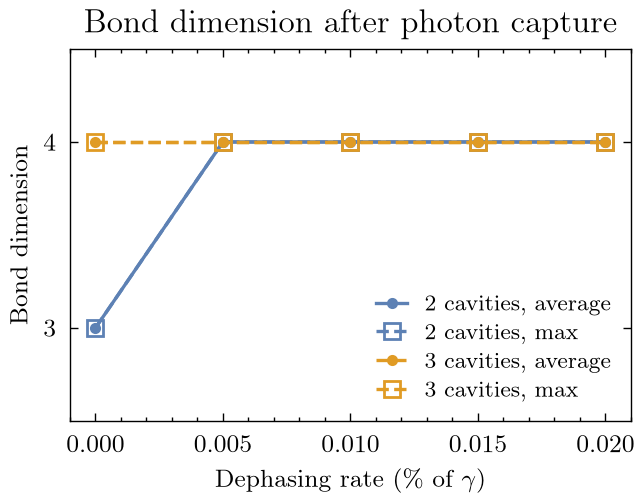

In [17]:
depha_list = collect(depha_list)   # same values as the sweep above
fig, ax = plt.subplots(figsize=(3.4, 2.4))
# colour = number of cavities; filled circles + solid = average, open squares + dashed = max.
# Average and max often coincide (always for 2 cavities, which have a single bond), so the open square is drawn
# larger and on top, letting the filled circle show through instead of one line hiding the other.
for (n, avg_list, max_list, c) in ((2, avg_bonddim_5, max_bonddim_5, "C0"), (3, avg_bonddim_10, max_bonddim_10, "C1"))
    ax.plot(depha_list, avg_list, color=c, lw=1.2, marker="o", ms=3, label="$n cavities, average")
    ax.plot(depha_list, max_list, color=c, lw=1.2, ls="--", marker="s", ms=6, mfc="none", mew=1.0, label="$n cavities, max")
end
# bond dimensions are integers: integer ticks, with a margin so points on the edge aren't clipped by the frame
ax.yaxis.set_major_locator(plt.matplotlib.ticker.MaxNLocator(integer=true))
ax.yaxis.set_minor_locator(plt.matplotlib.ticker.NullLocator())
lo = minimum(vcat(avg_bonddim_5, avg_bonddim_10)); hi = maximum(vcat(max_bonddim_5, max_bonddim_10))
ax.set_ylim(lo - 0.5, hi + 0.5)
ax.set_xlabel(raw"Dephasing rate (\% of $\gamma$)")
ax.set_ylabel("Bond dimension")
ax.set_title("Bond dimension after photon capture")
ax.legend(frameon=false)
# fig.savefig("Ch1_bonddim.pdf", bbox_inches="tight")
fig   # last value is shown; VS Code Julia notebooks don't display matplotlib figures on their own

Change in bond dim with time 

In [11]:
no_cavs = 5  #for placeholder graph
# no_cavs = 10   #for actual graph
depha = 0.02


# 4th return value: bond dims of the full emitter+cavities chain after every accepted step
mpo, sites, e_vals, (t_hist, linkdims_hist) = MPOFuncs.capture_photon(no_cavs, depha, gamma, dt, t_final)

[==============================] t = 20.0/20.0  dt = 0.00035  χ = 4  elapsed 4m18s  ETA ~0s           .0  dt = 0.00035  χ = 9  elapsed 45s  ETA ~1568m25s    


(ITensorMPS.MPO(5), ITensors.Index{Int64}[(dim=3|id=709|"Qudit,Site,n=2"), (dim=3|id=669|"Qudit,Site,n=3"), (dim=3|id=868|"Qudit,Site,n=4"), (dim=3|id=171|"Qudit,Site,n=5"), (dim=3|id=64|"Qudit,Site,n=6")], [0.9805173963309567, 0.010486751384789461, 0.0031879868099049815, 0.0015257943048339402, 0.0008924670279986517], ([0.0, 1.0e-5, 6.0e-5, 0.00015989377376232064, 0.00027146282858078307, 0.00040852280079976957, 0.00046939805604728443, 0.0005150935749271847, 0.0005717632408714684, 0.0006101238319649163  …  19.199645071967485, 19.299645071967486, 19.399645071967488, 19.49964507196749, 19.59964507196749, 19.699645071967492, 19.799645071967493, 19.899645071967495, 19.999645071967496, 20.0], [[1, 1, 1, 1, 1], [4, 4, 4, 4, 3], [4, 4, 4, 4, 4], [4, 4, 4, 6, 4], [4, 4, 4, 4, 4], [4, 4, 4, 6, 6], [4, 4, 4, 7, 8], [4, 4, 4, 7, 9], [4, 4, 4, 8, 9], [4, 4, 4, 7, 9]  …  [3, 6, 4, 4, 4], [3, 6, 4, 4, 4], [3, 6, 4, 4, 4], [3, 6, 4, 4, 4], [3, 6, 4, 4, 4], [3, 5, 4, 4, 4], [3, 4, 4, 4, 4], [3, 4, 4, 4

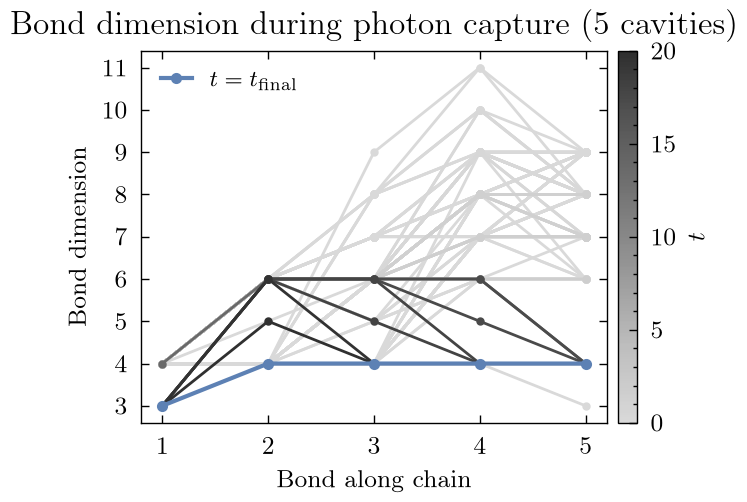

In [35]:
# A grey line for every recorded step (the final step is the blue line). Runs of consecutive steps with the same
# profile are drawn once, at the last step of the run: identical lines would just be painted over each other, and this
# keeps the figure light (there can be thousands of steps) while looking exactly the same.
# The initial product state (every bond dimension 1) is left out.
snap_idx = [i for i in 1:length(t_hist)-1 if linkdims_hist[i] != linkdims_hist[i+1] && !all(==(1), linkdims_hist[i])]
bonds = 1:length(linkdims_hist[end])     # bond 1 = emitter-cavity 1, bond i = cavity i-1 - cavity i

fig, ax = plt.subplots(figsize=(3.4, 2.4))
# grey shade darkens with time (light = early, dark = late). Solid opaque greys rather than alpha: many snapshots
# share the same integer profile, and overlapping transparent lines stack up and hide the time ordering.
# ls="-" everywhere: physrev.mplstyle cycles the line style along with the colour, so lines would otherwise
# come out dashed/dotted in turn (that is why the final line was dashed).
greys = plt.matplotlib.colormaps["Greys"]
# shade by the actual time (steps are irregular, so the step number would bunch the shades near t = 0)
shade_frac(t) = 0.25 + 0.6 * t / t_final
for i in snap_idx
    ax.plot(bonds, linkdims_hist[i], color=greys(shade_frac(t_hist[i])), ls="-", lw=1.0, marker="o", ms=2)
end
ax.plot(bonds, linkdims_hist[end], color="C0", ls="-", lw=1.5, marker="o", ms=3, zorder=3, label=raw"$t = t_\mathrm{final}$")
# colour bar maps the grey shade back to time
sm = plt.matplotlib.cm.ScalarMappable(cmap=plt.matplotlib.colors.ListedColormap([plt.matplotlib.colors.to_hex(greys(shade_frac(t))) for t in range(0, t_final, length=256)]),
                                      norm=plt.matplotlib.colors.Normalize(0, t_final))
fig.colorbar(sm, ax=ax, label=raw"$t$", pad=0.02)
ax.yaxis.set_major_locator(plt.matplotlib.ticker.MaxNLocator(integer=true))
ax.yaxis.set_minor_locator(plt.matplotlib.ticker.NullLocator())
ax.xaxis.set_minor_locator(plt.matplotlib.ticker.NullLocator())
ax.set_xlabel("Bond along chain")
ax.set_ylabel("Bond dimension")
ax.set_title("Bond dimension during photon capture ($no_cavs cavities)")
ax.set_xticks(bonds)
ax.legend(frameon=false)
# fig.savefig("Ch1_bonddim_time.pdf", bbox_inches="tight")
fig   # last value is shown; VS Code Julia notebooks don't display matplotlib figures on their own

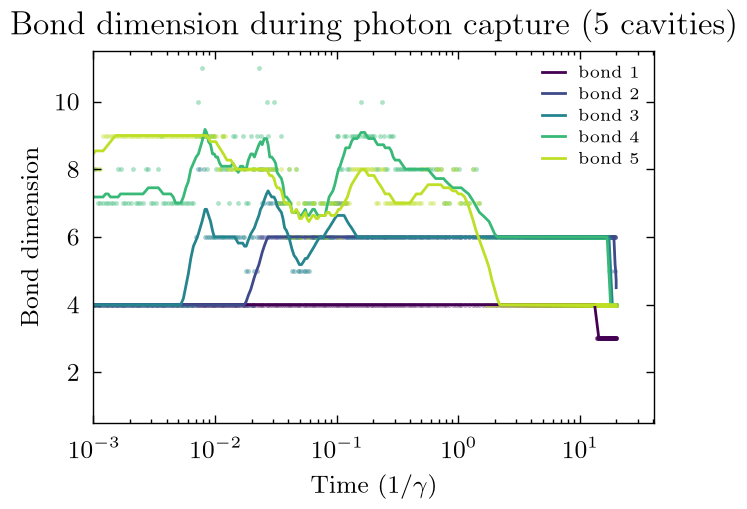

In [36]:
# How each bond dimension evolves in time, using every recorded step: the raw values as faint points, and a
# sliding average over `window` consecutive steps as a line. The raw values flicker by 1-3 from step to step
# (singular values sitting at the truncation cutoff), which the average smooths out.
window = 10
nb_bonds = length(linkdims_hist[end])     # bond 1 = emitter-cavity 1, bond i = cavity i-1 - cavity i
ld_mat = reduce(hcat, linkdims_hist)'     # rows = time steps, columns = bonds

fig, ax = plt.subplots(figsize=(3.4, 2.4))
# colour runs along the chain (bond 1 dark -> last bond light); ls="-" because physrev.mplstyle cycles line styles
bond_colour(b) = plt.matplotlib.colors.to_hex(plt.matplotlib.colormaps["viridis"](0.9 * (b - 1) / max(nb_bonds - 1, 1)))
# centred average over steps (not time: the adaptive steps are irregular); the window shrinks at the two ends
half = window ÷ 2
moving_avg(y) = [sum(y[max(1, k-half):min(end, k+half)]) / length(max(1, k-half):min(length(y), k+half)) for k in eachindex(y)]
for b in 1:nb_bonds
    ax.scatter(t_hist, ld_mat[:, b], color=bond_colour(b), s=3, alpha=0.4, linewidths=0)
    ax.plot(t_hist, moving_avg(ld_mat[:, b]), color=bond_colour(b), ls="-", lw=1.0, label="bond $b")
end
ax.yaxis.set_major_locator(plt.matplotlib.ticker.MaxNLocator(integer=true))
ax.yaxis.set_minor_locator(plt.matplotlib.ticker.NullLocator())
# log time: the bond dimensions do most of their changing for t ≲ 2, where the adaptive steps are tiny
# (first step 1e-5), and are then flat; a linear axis squashes all of that against t = 0. t = 0 itself can't be shown.
ax.set_xscale("log")
ax.set_xlim(left=1e-3)
ax.set_xlabel(raw"Time ($1/\gamma$)")
ax.set_ylabel("Bond dimension")
ax.set_title("Bond dimension during photon capture ($no_cavs cavities)")
ax.legend(frameon=false, fontsize=6, ncol=nb_bonds > 5 ? 2 : 1)
# fig.savefig("Ch1_bonddim_vs_time.pdf", bbox_inches="tight")
fig   # last value is shown; VS Code Julia notebooks don't display matplotlib figures on their own

# Indistinguishability

For 10/15 cavities indistinguishability vs dephasing (with analytic comparison)

In [19]:
dist_10 = []        # distinguishability (1 - I)/2 from the MPO simulation
dist_15 = []
num_ideal_10 = []   # same if the first n modes were captured perfectly: 0.5(1 - Σnᵢ²/(Σnᵢ)²)
num_ideal_15 = []

# cav1, cav2 = 10,15  #for actual graph
cav1, cav2 = 2,3  #for placeholder graph

depha_ind = 0:0.005:0.02   # dephasing values for the sweep (the plots below reuse this)

for depha in depha_ind
    println(depha)
    for (n, dist_list, ideal_list) in ((cav1, dist_10, num_ideal_10), (cav2, dist_15, num_ideal_15))
        mpo, sites, e_vals = MPOFuncs.capture_photon(n, depha, gamma, dt, t_final)
        # two copies, interleaved so cavity i of each copy are neighbours, then a beamsplitter on each pair
        double, double_sites = MPOFuncs.n_copy_mpo(mpo, sites, 2)
        for i in n:-1:1
            double = MPOFuncs.swap_ij!(double, double_sites, i, 2*i-1)
            MPOFuncs.beamsplitter_nextsite!(double, double_sites, 2*i-1)
        end
        push!(dist_list, real(MPOFuncs.g_34_new(double, double_sites, n)))
        push!(ideal_list, 0.5 * (1 - sum(e_vals.^2) / sum(e_vals)^2))
    end
end

0.0
[==============================] t = 20.0/20.0  dt = 0.0099  χ = 3  elapsed 17s  ETA ~0s         


┌ Warning: JSON-RPC endpoint has been blocked writing to its peer; outgoing messages are queueing up and will not be delivered until the peer resumes reading
│   blocked_seconds = 284.7
│   queued_messages = 1
└ @ VSCodeServer.JSONRPC /Users/ygup3491/.vscode/extensions/julialang.language-julia-1.250.2/scripts/packages/JSONRPC/src/core.jl:414


[==============================] t = 20.0/20.0  dt = 0.095  χ = 4  elapsed 11m21s  ETA ~0s       
0.005
[==============================] t = 20.0/20.0  dt = 0.028  χ = 4  elapsed 1m50s  ETA ~0s        
[==============================] t = 20.0/20.0  dt = 0.083  χ = 4  elapsed 15m30s  ETA ~0s       
0.01
[==============================] t = 20.0/20.0  dt = 0.027  χ = 4  elapsed 15m14s  ETA ~0s       
[==============================] t = 20.0/20.0  dt = 0.032  χ = 4  elapsed 37s  ETA ~0s          
0.015
[==============================] t = 20.0/20.0  dt = 0.027  χ = 4  elapsed 14s  ETA ~0s          
[==============================] t = 20.0/20.0  dt = 0.072  χ = 4  elapsed 29s  ETA ~0s          
0.02
[==============================] t = 20.0/20.0  dt = 0.027  χ = 4  elapsed 10s  ETA ~0s          
[==============================] t = 20.0/20.0  dt = 0.07  χ = 4  elapsed 27s  ETA ~0s           


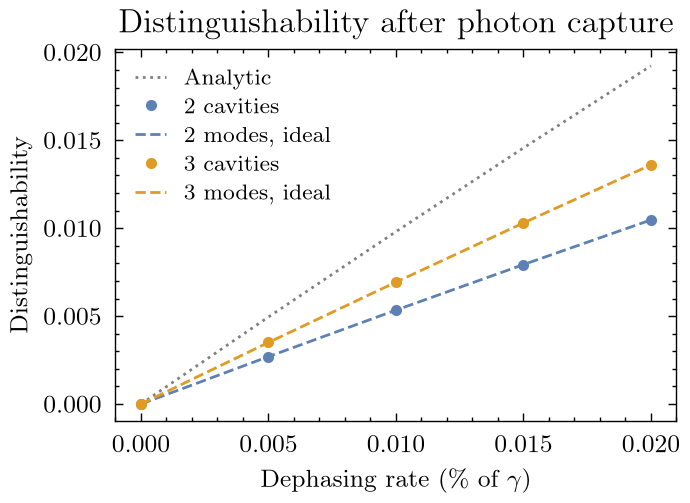

In [30]:
depha_list = collect(depha_ind)   # same values as the sweep above
# (1 - I)/2 with I = γ/(γ + 2·deph), deph being the coherence dephasing rate (√(deph/2) σz, as in g2/drho)
abs_ideal = depha_list ./ (gamma .+ 2 .* depha_list)

fig, ax = plt.subplots(figsize=(3.4, 2.4))
ax.plot(depha_list, abs_ideal, color="grey", lw=1.0, ls=":", label="Analytic")
# colour = number of cavities, markers = MPO simulation, dashed = perfect capture of the first n modes
for (n, dist_list, ideal_list, c) in ((cav1, dist_10, num_ideal_10, "C0"), (cav2, dist_15, num_ideal_15, "C1"))
    ax.plot(depha_list, dist_list, color=c, ls="none", marker="o", ms=3, label="$n cavities")
    ax.plot(depha_list, ideal_list, color=c, lw=1.0, ls="--", label="$n modes, ideal")
end
ax.set_xlabel(raw"Dephasing rate (\% of $\gamma$)")
ax.set_ylabel("Distinguishability")
ax.set_title("Distinguishability after photon capture")
ax.legend(frameon=false)
# fig.savefig("Ch1_distinguishability.pdf", bbox_inches="tight")
fig   # last value is shown; VS Code Julia notebooks don't display matplotlib figures on their own

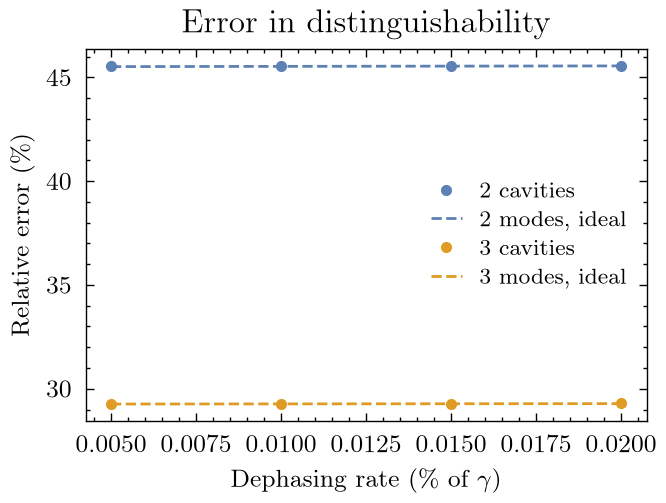

In [29]:
fig, ax = plt.subplots(figsize=(3.4, 2.4))
# relative error against the analytic value; depha = 0 is skipped since the analytic value is 0 there
for (n, dist_list, ideal_list, c) in ((cav1, dist_10, num_ideal_10, "C0"), (cav2, dist_15, num_ideal_15, "C1"))
    ax.plot(depha_list[2:end], 100 .* abs.(dist_list[2:end] .- abs_ideal[2:end]) ./ abs_ideal[2:end],
            color=c, ls="none", marker="o", ms=3, label="$n cavities")
    ax.plot(depha_list[2:end], 100 .* abs.(ideal_list[2:end] .- abs_ideal[2:end]) ./ abs_ideal[2:end],
            color=c, lw=1.0, ls="--", label="$n modes, ideal")
end
ax.set_xlabel(raw"Dephasing rate (\% of $\gamma$)")
ax.set_ylabel(raw"Relative error (\%)")
ax.set_title("Error in distinguishability")
ax.legend(frameon=false)
# fig.savefig("Ch1_distinguishability_err.pdf", bbox_inches="tight")
fig   # last value is shown; VS Code Julia notebooks don't display matplotlib figures on their own

# Bell state

Linear MPO

In [ ]:
using ITensorMPS: MPO, siteinds, truncate!
ncav_lin = 1  #for placeholder graph
# ncav_lin = 2  #for actual graph
depha = 0.02

# whole Bell state generator (4 photons + 4 ancillas per cavity mode) as one linear MPO; bond dims after each stage
stage_names = ["4 copies", "signal-ancilla BS", "ancillas moved to end", "ancilla BS"]
stage_linkdims = []

mpo, sites, e_vals = MPOFuncs.capture_photon(ncav_lin, depha, gamma, dt, t_final)
# one ancilla per cavity, joined after the photon then swapped in so each cavity sits next to its ancilla
ancilla_sites = siteinds("Qudit", ncav_lin, dim=3)
ancilla = MPO(ancilla_sites, repeat(["Ground",], ncav_lin))
sys, sys_sites = MPOFuncs.join(mpo, sites, ancilla, ancilla_sites)
for i in ncav_lin:-1:1
    sys = MPOFuncs.swap_ij!(sys, sys_sites, i, 2i-1)
end
full, full_sites = MPOFuncs.n_copy_mpo(sys, sys_sites, 4)
push!(stage_linkdims, linkdims(full))

# beamsplitter between each cavity and its ancilla, in every copy
for i in 1:4, j in 1:ncav_lin
    MPOFuncs.beamsplitter_nextsite!(full, full_sites, 2ncav_lin*(i-1) + 2j-1)
end
truncate!(full; cutoff=1e-10)
push!(stage_linkdims, linkdims(full))

# move the ancillas to the end of the chain: ancilla of copy i, cavity j ends up at 4n + n(i-1) + j
for i in 1:4, j in 1:ncav_lin
    full = MPOFuncs.swap_ij!(full, full_sites, ncav_lin*(i-1) + j + 1, 8ncav_lin)
end
push!(stage_linkdims, linkdims(full))

# beamsplitters between the ancilla copies (1-2 and 3-4, then 1-4 and 2-3)
for j in 1:ncav_lin
    MPOFuncs.beamsplitter!(full, full_sites, 4ncav_lin+j, 5ncav_lin+j)
    MPOFuncs.beamsplitter!(full, full_sites, 6ncav_lin+j, 7ncav_lin+j)
end
for j in 1:ncav_lin
    MPOFuncs.beamsplitter!(full, full_sites, 4ncav_lin+j, 7ncav_lin+j)
    MPOFuncs.beamsplitter!(full, full_sites, 5ncav_lin+j, 6ncav_lin+j)
end
push!(stage_linkdims, linkdims(full))

In [ ]:
bonds = 1:length(stage_linkdims[end])

fig, ax = plt.subplots(figsize=(3.4, 2.4))
for (k, (name, ld)) in enumerate(zip(stage_names, stage_linkdims))
    ax.plot(bonds, ld, color="C$(k-1)", lw=1.0, marker="o", ms=3, label=name)
end
ax.set_yscale("log", base=2)    # bond dims grow by factors of 4 per bond
ax.set_xlabel("Bond along chain")
ax.set_ylabel("Bond dimension")
ax.set_title("Linear MPO Bell state generator ($n_lin cavities)")
ax.set_xticks(bonds)
ax.legend(frameon=false)
# fig.savefig("Ch1_bell_linear_bonddim.pdf", bbox_inches="tight")
fig   # last value is shown; VS Code Julia notebooks don't display matplotlib figures on their own

PEPS MPO

In [ ]:
using JLD2
n_bell = 2  #for placeholder graph
# n_bell = 7  #for actual graph
data_dir = "../../Data/"    # repo Data/ folder (the notebook runs from Code/Ch1RelCode)
err_types = ("IX", "XI", "IZ", "ZI", "XZ", "ZX")

# everything below except prob is divided by prob, i.e. taken on the heralded state
prob_bell = []      # heralding (1100 detection) probability
fidel_bell = []     # fidelity with the ideal Bell state
visib_bell = []     # V = Σnᵢ² over every mode of the photon (not just the n_bell captured)
f_exact_bell = []   # analytic fidelity from the mode occupations nᵢ
stab_bell = Dict(s => [] for s in ("XX", "ZZ", "YY"))
err_bell = Dict(e => [] for e in err_types)

for depha in 0:0.0025:0.02
    println(depha)
    name = data_dir * "peps_dep" * string(trunc(Int, depha*10000)) * "no_cavs" * string(n_bell) * "tf" * string(Int(t_final))
    # simulate and save one cavity mode at a time; skipped if this run is already saved
    if !isfile(name * ".jld2")
        mpo, sites, e_vals = MPOFuncs.capture_photon(n_bell, depha, gamma, dt, t_final)
        peps, peps_sites = MPOFuncs.bell_peps_init(mpo, sites, n_bell)
        detect_mpo = MPOFuncs.detect_1100_anymode(peps_sites[2,:])
        comb = 1
        for i in 0:n_bell-1
            top, bottom, comb = MPOFuncs.bell_peps_mode!(peps, peps_sites, detect_mpo, i, comb)
            jldsave(name * "part_" * string(i+1) * ".jld2"; top, bottom)
        end
        jldsave(name * ".jld2"; peps_sites)    # written last, so it only exists once every mode is saved
    end

    _, e_full = MPOFuncs.g2(gamma, depha, t_final, dt, n_bell)
    n_modes = e_full ./ sum(e_full)
    V = sum(n_modes.^2)
    push!(visib_bell, V)
    push!(f_exact_bell, (1 + V + V^2 + sum(n_modes.^4)) / (6 - 2V))

    peps_sites = load(name * ".jld2", "peps_sites")
    tops = [load(name * "part_" * string(i) * ".jld2", "top") for i in 1:n_bell]
    bottoms = [load(name * "part_" * string(i) * ".jld2", "bottom") for i in 1:n_bell]
    signal = peps_sites[1,:]
    prob = real(MPOFuncs.peps_measure(tops, bottoms, peps_sites))
    push!(prob_bell, prob)
    push!(fidel_bell, real(MPOFuncs.peps_measure(tops, bottoms, peps_sites, MPOFuncs.ideal_bell(signal))) / prob)
    # stabalizer_gen's three operators give +1, -1, -1 on the ideal Bell state; flipped so all three are +1
    for (s, sgn, stab) in zip(("XX", "ZZ", "YY"), (1, -1, -1), MPOFuncs.stabalizer_gen(signal))
        push!(stab_bell[s], sgn * real(MPOFuncs.peps_measure(tops, bottoms, peps_sites, stab)) / prob)
    end
    for e in err_types
        push!(err_bell[e], real(MPOFuncs.peps_measure(tops, bottoms, peps_sites, MPOFuncs.error_bell(e, signal))) / prob)
    end
end

In [ ]:
F_up(V) = (1 + V + 2V^2)/(6-2V)
F_down(V) = (1 + 4V + 3V^2)/(12-4V)

fig, ax = plt.subplots(figsize=(3.4, 2.4))
ax.plot(visib_bell, f_exact_bell, color="k", lw=1.0, label="Analytic")
ax.plot(visib_bell, F_up.(visib_bell), color="grey", lw=1.0, ls="--", label="Upper/lower bound")
ax.plot(visib_bell, F_down.(visib_bell), color="grey", lw=1.0, ls="--")
ax.plot(visib_bell, fidel_bell, color="C0", ls="none", marker="o", ms=3, label="$n_bell cavities")
ax.set_xlabel(raw"Visibility $V = \sum_i n_i^2$")
ax.set_ylabel("Bell state fidelity")
ax.set_title("Bell state fidelity vs photon visibility")
ax.legend(frameon=false)
# fig.savefig("Ch1_bell_fidelity.pdf", bbox_inches="tight")
fig   # last value is shown; VS Code Julia notebooks don't display matplotlib figures on their own

In [ ]:
depha_list = collect(0:0.0025:0.02)
fig, ax = plt.subplots(figsize=(3.4, 2.4))
ax.axhline(1/32, color="k", lw=1.0, ls="--", label="Ideal (1/32)")
ax.plot(depha_list, prob_bell, color="C0", ls="none", marker="o", ms=3, label="$n_bell cavities")
ax.set_xlabel(raw"Dephasing rate (\% of $\gamma$)")
ax.set_ylabel("Success probability")
ax.set_title("Bell state heralding probability")
ax.legend(frameon=false)
# fig.savefig("Ch1_bell_prob.pdf", bbox_inches="tight")
fig   # last value is shown; VS Code Julia notebooks don't display matplotlib figures on their own

In [ ]:
fig, ax = plt.subplots(figsize=(3.4, 2.4))
for (k, s) in enumerate(("XX", "ZZ", "YY"))
    ax.plot(depha_list, stab_bell[s], color="C$(k-1)", lw=1.0, marker="o", ms=3, label=s)
end
ax.set_xlabel(raw"Dephasing rate (\% of $\gamma$)")
ax.set_ylabel("Stabiliser expectation")
ax.set_title("Bell state stabilisers ($n_bell cavities)")
ax.legend(frameon=false)
# fig.savefig("Ch1_bell_stabilisers.pdf", bbox_inches="tight")
fig   # last value is shown; VS Code Julia notebooks don't display matplotlib figures on their own

In [ ]:
fig, ax = plt.subplots(figsize=(3.4, 2.4))
for (k, e) in enumerate(err_types)
    ax.plot(depha_list, err_bell[e], color="C$(k-1)", lw=1.0, marker="o", ms=3, label=e)
end
ax.set_xlabel(raw"Dephasing rate (\% of $\gamma$)")
ax.set_ylabel("Error weight")
ax.set_title("Pauli errors on the Bell state ($n_bell cavities)")
ax.legend(frameon=false, ncol=2)
# fig.savefig("Ch1_bell_errors.pdf", bbox_inches="tight")
fig   # last value is shown; VS Code Julia notebooks don't display matplotlib figures on their own

# GHZ State

# Fusion
